# Tutorial: Geometry Module in Soft Potato

The `softpotato.geometry` module handles spatial coordinate systems and geometric transformations in Soft Potato. In electrochemical and physical simulations, diffusion behavior strongly depends on electrode geometry. The **geometry module** provides built-in support for:

- **Planar Geometry** (`PlanarGeometry` or `"planar"`): 1D Cartesian diffusion to flat surfaces.
- **Cylindrical Geometry** (`CylindricalGeometry` or `"cylindrical"`): 2D radial diffusion to micro-wires or cylinders.
- **Spherical Geometry** (`SphericalGeometry` or `"spherical"`): 3D convergent radial diffusion to spheres or droplets.

In this tutorial, we focus on the **spherical geometry**, demonstrating the minimal code needed to configure a spherical diffusion domain, run a numerical simulation, and visualize the resulting concentration profiles and Faradaic current.

---

## 1. Minimal Code to Use Spherical Geometry

To simulate diffusion to a spherical electrode of radius $r_0$, instantiate `SphericalGeometry(r0=r0)` and pass it directly to `DiffusionProblem`. The radial grid starts at the electrode surface $r = r_0$ and extends into the bulk solution ($r_0 + \delta$).

In [12]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import interp1d
from softpotato.geometry import SphericalGeometry
from softpotato.solver import DiffusionProblem, DirichletBC, get_solver
from softpotato.analytical.step import cottrell_spherical

# 1. Physical and domain parameters
r0 = 25e-6          # Electrode radius: 25 µm
D = 1e-9            # Diffusion coefficient: 1e-9 m²/s
c_bulk = 1.0        # Bulk concentration: 1.0 mol/m³ (1.0 mM)
n = 1               # Number of electrons transferred
t_max = 1.0         # Total simulation time: 1.0 s

# Diffusion layer thickness
delta = 6.0 * np.sqrt(D * t_max)
r_grid = np.linspace(r0, r0 + delta, 150)

# 2. Configure spherical geometry
geom = SphericalGeometry(r0=r0)

# 3. Formulate the diffusion problem
problem = DiffusionProblem(
    grid=r_grid,
    diffusivity={"c": D},
    boundary_conditions={"c": (DirichletBC(0.0), DirichletBC(c_bulk))},
    initial_conditions={"c": c_bulk},
    geometry=geom,
    n_electrons=n,
)

# 4. Solve the problem
solver = get_solver("scipy_ivp")
t_eval = np.linspace(0.01, t_max, 100)
result = solver.solve(problem, t_span=(0.0, t_max), t_eval=t_eval)

print(f"Simulation completed: {result.message}")
print(f"Concentration profile shape: {result['c'].shape}")

Simulation completed: SciPy solve_ivp completed successfully.
Concentration profile shape: (100, 150)


---

## 2. Concentration Profile in Radial Coordinate ($r$)

Because of spherical symmetry, diffusion depends only on the radial distance $r$. We can plot the concentration profile $c(r)$ at several time snapshots from the electrode surface ($r = r_0$) into the bulk solution.

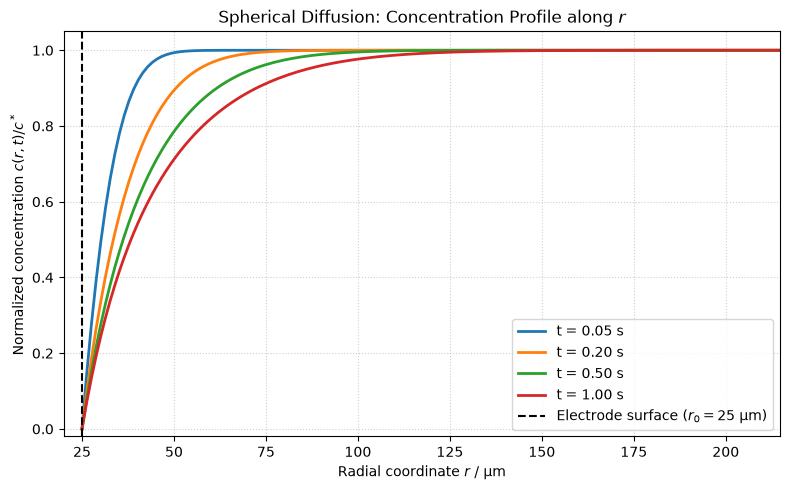

In [13]:
# Select time snapshots to display
snapshots = [0.05, 0.20, 0.50, 1.00]
colors = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728"]

fig, ax = plt.subplots(figsize=(8, 5))

for t_target, color in zip(snapshots, colors):
    idx = np.argmin(np.abs(result.t - t_target))
    t_actual = result.t[idx]
    ax.plot(
        r_grid * 1e6,
        result["c"][idx] / c_bulk,
        color=color,
        lw=2,
        label=f"t = {t_actual:.2f} s",
    )

ax.axvline(
    r0 * 1e6,
    color="black",
    linestyle="--",
    lw=1.5,
    label=f"Electrode surface ($r_0 = {r0 * 1e6:.0f}$ µm)",
)

ax.set_xlabel("Radial coordinate $r$ / µm")
ax.set_ylabel("Normalized concentration $c(r, t) / c^*$")
ax.set_title("Spherical Diffusion: Concentration Profile along $r$")
ax.set_xlim(r0 * 1e6 - 5, (r0 + delta) * 1e6)
ax.set_ylim(-0.02, 1.05)
ax.grid(True, linestyle=":", alpha=0.6)
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

---

## 3. Concentration Profile in 2D Cartesian Coordinates ($x, y$)

Viewing a spherical electrode in an equatorial 2D slice ($z = 0$) maps the 1D radial coordinate $r$ into 2D Cartesian coordinates where:

$$r = \sqrt{x^2 + y^2}$$

The region $r < r_0$ represents the solid electrode interior, while $r \ge r_0$ represents the surrounding electrolyte where diffusion takes place.

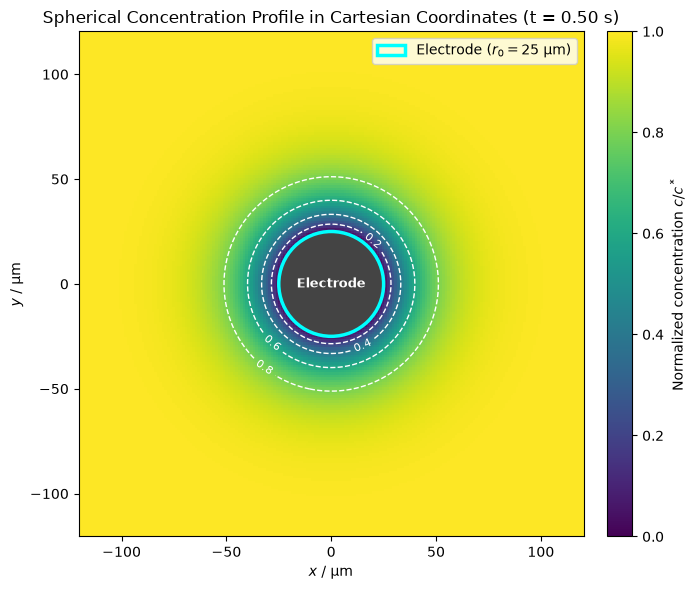

In [14]:
# 1. Create a 2D Cartesian grid
r_view = r0 + 0.5 * delta
n_grid = 200
x_vals = np.linspace(-r_view, r_view, n_grid) * 1e6  # in µm
y_vals = np.linspace(-r_view, r_view, n_grid) * 1e6
X, Y = np.meshgrid(x_vals, y_vals)
R = np.sqrt(X**2 + Y**2) * 1e-6                     # in meters

# 2. Interpolate the radial profile at t = 0.5 s onto the 2D grid
t_target = 0.5
t_idx = np.argmin(np.abs(result.t - t_target))
c_interp = interp1d(
    r_grid,
    result["c"][t_idx] / c_bulk,
    bounds_error=False,
    fill_value=(0.0, 1.0),
)
C_2d = c_interp(R)

# Mask the electrode interior (r < r0)
C_2d[R < r0] = np.nan

# 3. Plot the 2D concentration map
cmap = plt.cm.viridis.copy()
cmap.set_bad(color="#444444")

fig, ax = plt.subplots(figsize=(7, 6))

mesh = ax.pcolormesh(X, Y, C_2d, cmap=cmap, vmin=0.0, vmax=1.0, shading="auto")
contours = ax.contour(
    X,
    Y,
    C_2d,
    levels=[0.2, 0.4, 0.6, 0.8],
    colors="white",
    linewidths=1.0,
    linestyles="--",
)
ax.clabel(contours, inline=True, fontsize=8, fmt="%.1f")

# Draw the spherical electrode cross-section
electrode_circle = plt.Circle(
    (0, 0),
    r0 * 1e6,
    color="cyan",
    fill=False,
    lw=2.5,
    label=f"Electrode ($r_0 = {r0 * 1e6:.0f}$ µm)",
)
ax.add_patch(electrode_circle)
ax.text(0, 0, "Electrode", color="white", ha="center", va="center", fontsize=9, fontweight="bold")

cbar = fig.colorbar(mesh, ax=ax, fraction=0.046, pad=0.04)
cbar.set_label("Normalized concentration $c / c^*$")

ax.set_aspect("equal")
ax.set_xlabel("$x$ / µm")
ax.set_ylabel("$y$ / µm")
ax.set_title(f"Spherical Concentration Profile in Cartesian Coordinates (t = {result.t[t_idx]:.2f} s)")
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

---

## 4. Faradaic Current Transient

In Soft Potato, simulated Faradaic currents are automatically evaluated from the surface concentration gradient and made accessible via `result.currents`.

For a spherical electrode, the current transient combines the short-time planar Cottrell decay with a non-zero steady-state limit:

$$I_{\text{ss}} = 4 \pi n F D c^* r_0$$

Below, we plot the simulated Faradaic current alongside the analytical spherical Cottrell equation.

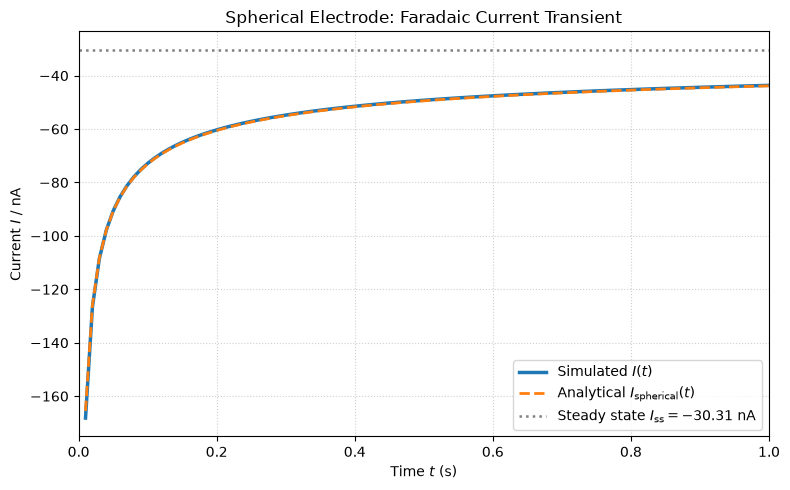

In [15]:
# Simulated current from SolverResult
current_sim = result.currents["c"]

# Analytical spherical Cottrell current
current_ana = -cottrell_spherical(
    result.t, r=r0, n=n, D=D, c_bulk=c_bulk, area=geom.area
)

# Steady-state limiting current
i_ss = -4.0 * np.pi * n * 96485.33212 * D * c_bulk * r0

fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(result.t, current_sim * 1e9, "tab:blue", lw=2.5, label="Simulated $I(t)$")
ax.plot(
    result.t,
    current_ana * 1e9,
    "tab:orange",
    linestyle="--",
    lw=2.0,
    label="Analytical $I_{\\mathrm{spherical}}(t)$",
)
ax.axhline(
    i_ss * 1e9,
    color="gray",
    linestyle=":",
    lw=1.8,
    label=f"Steady state $I_{{\\mathrm{{ss}}}} = {i_ss * 1e9:.2f}$ nA",
)

ax.set_xlabel("Time $t$ (s)")
ax.set_ylabel("Current $I$ / nA")
ax.set_title("Spherical Electrode: Faradaic Current Transient")
ax.set_xlim(0, t_max)
ax.grid(True, linestyle=":", alpha=0.6)
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

---

## Summary and API Reference

In this tutorial, we configured a spherical diffusion domain using the `softpotato.geometry` module with minimal code:

1. **Instantiate Geometry:** Create `SphericalGeometry(r0=r0)` to specify the electrode radius and spatial coordinate behavior.
2. **Formulate Problem:** Pass the geometry to `DiffusionProblem(..., geometry=geom)`.
3. **Solve and Visualize:** Run `solver.solve()` to obtain concentration profiles in radial coordinates $c(r)$, reconstruct 2D Cartesian cross-sections, and inspect the Faradaic current transient via `result.currents`.

For complete details on all geometry classes, coordinate transformations, and options, visit the [Geometry Module API Reference](../../../api/geometry/).